In [3]:
from ultralytics import YOLO
import time
import os
import pandas as pd
import cv2
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import numpy as np
import shutil
from tqdm import tqdm

In [7]:
def draw_ground_truth(image_path, label_path):
    """
    Draws YOLO bounding boxes on an image.

    Args:
        image_path (str): Path to the image file.
        label_path (str): Path to the YOLO format label file.
        box_color (str): Color of the bounding boxes (default: "red").
    
    Returns:
        PIL.Image: Image with bounding boxes drawn.
    """
    # Load the image
    original_image = Image.open(image_path)
    image_width, image_height = original_image.size

    # Read YOLO label file
    try:
        with open(label_path, "r") as f:
            lines = f.readlines()
    except FileNotFoundError:
        print(f"Warning: No label file found for {image_path}")
        return original_image  # Return image without annotations

    # Draw bounding boxes
    draw = ImageDraw.Draw(original_image)
    for line in lines:
        data = line.strip().split()
        class_id = int(data[0])  # First value is class ID
        if class_id == 0:
            box_color = "red"
        elif class_id == 1:
            box_color = "blue"
        elif class_id == 2:
            box_color = "green"
        elif class_id == 3:
            box_color = "yellow"
        x_center, y_center, w, h = map(float, data[1:])  # YOLO format (normalized)

        # Convert YOLO format to pixel coordinates
        x1 = int((x_center - w / 2) * image_width)
        y1 = int((y_center - h / 2) * image_height)
        x2 = int((x_center + w / 2) * image_width)
        y2 = int((y_center + h / 2) * image_height)

        # Draw rectangle (customizable color)
        draw.rectangle([x1, y1, x2, y2], outline=box_color, width=3)

    return original_image

def get_prediction_image(model, image_path):
    """
    Runs model inference on an image and converts the prediction output to a PIL image.

    Args:
        model: Trained object detection model.
        image_path (str): Path to the input image.
    
    Returns:
        PIL.Image: Model's prediction visualization.
    """
    results = model(image_path)
    predicted_array = results[0].plot()  # Get model's prediction visualization
    return Image.fromarray(np.uint8(predicted_array))  # Convert to PIL image

def plot_prediction_image(image_path, model):
    """
    Displays the model's prediction output.

    Args:
        image_path (str): Path to the image file.
        model: Trained object detection model.
    """
    predicted_pil = get_prediction_image(model, image_path, )
    plt.imshow(predicted_pil)
    plt.axis("off")
    plt.show()

def plot_ground_truth_vs_prediction(image_path, label_path, model):
    """
    Displays the ground truth vs model prediction side by side.

    Args:
        image_path (str): Path to the image file.
        label_path (str): Path to the YOLO label file.
        model: Trained object detection model.
    """
    # Get ground truth and model prediction images
    gt_image = draw_ground_truth(image_path, label_path)
    predicted_pil = get_prediction_image(model, image_path)

    # Display both images side by side
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Ground Truth Image
    axes[0].imshow(gt_image)
    axes[0].set_title("Ground Truth (Red Boxes)")
    axes[0].axis("off")

    # Model Prediction Image
    axes[1].imshow(predicted_pil)
    axes[1].set_title("Model Prediction")
    axes[1].axis("off")

    plt.show()
def plot_test_inference(dataset_names, model):
    for dataset_name in dataset_names:
        base_path = os.path.join('separate_datasets_inv11', dataset_name, 'datasets')
        test_image_folder = os.path.join(base_path, 'images', 'val')
        test_label_folder = os.path.join(base_path, 'labels', 'val')

        test_image_path, test_label_path = get_test_image_label(test_image_folder, test_label_folder)

        plot_ground_truth_vs_prediction(test_image_path, test_label_path, model)

def get_test_image_label(test_image_folder, test_label_folder):
    random_image = random.choice(os.listdir(test_image_folder))
    test_image_path = os.path.join(test_image_folder, random_image)
    test_label_path = os.path.join(test_label_folder, f"{random_image.rsplit('.', 1)[0]}.txt")
    return test_image_path, test_label_path

def relabel(images_folder, labels_folder, model_path, conf):
    model = YOLO(model_path)
    
    for image in os.listdir(images_folder):
        if image.lower().endswith(('.jpg', '.png', '.jpeg')):  # Ensure only image files are processed
            image_path = os.path.join(images_folder, image)
            result = model.predict(image_path, conf=conf)[0]
            label_path = os.path.join(labels_folder, image.rsplit(".", 1)[0] + ".txt")
            result.save_txt(label_path)
            print(f"Saved: {label_path}")

def get_subset(full_train_image_dir, subset_images_dir, number_files):
    files = os.listdir(full_train_image_dir)
    random.shuffle(files)
    for i in tqdm(range(number_files)):
        file = files[i]
        shutil.copy(os.path.join(full_train_image_dir, file), subset_images_dir)
        # also copy label file
        label_file = file.split('.')[0] + '.txt'
        shutil.copy(os.path.join(full_train_image_dir.replace('images', 'labels'), label_file), subset_images_dir.replace('images', 'labels'))
    print(f"Done copying {number_files} files to {subset_images_dir}")

## Test out seperate model inference

### Label Doors

In [124]:
#door_model = YOLO("v11doorbest_float32.tflite", task = 'detect')
door_model = YOLO("sep_models/door_model_v2.pt", task = 'detect')


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\numbers_svhn\datasets\images\val\svhn_8374.jpg: 640x640 (no detections), 228.2ms
Speed: 15.6ms preprocess, 228.2ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


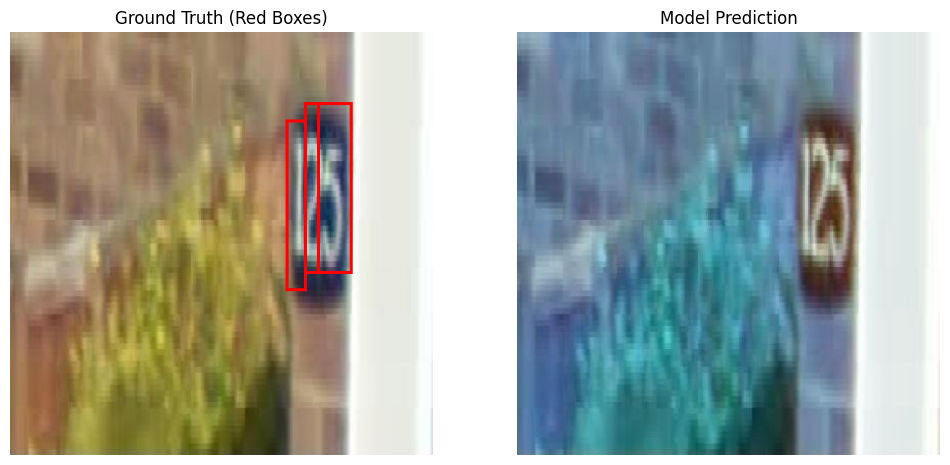

In [6]:
# iterate over all non-door dataset folders
dataset_names = ['numbers_svhn']

plot_test_inference(dataset_names, door_model)

image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\val\10132.jpg: 480x640 (no detections), 110.5ms
Speed: 0.0ms preprocess, 110.5ms inference, 0.0ms postprocess per image at shape (1, 3, 480, 640)


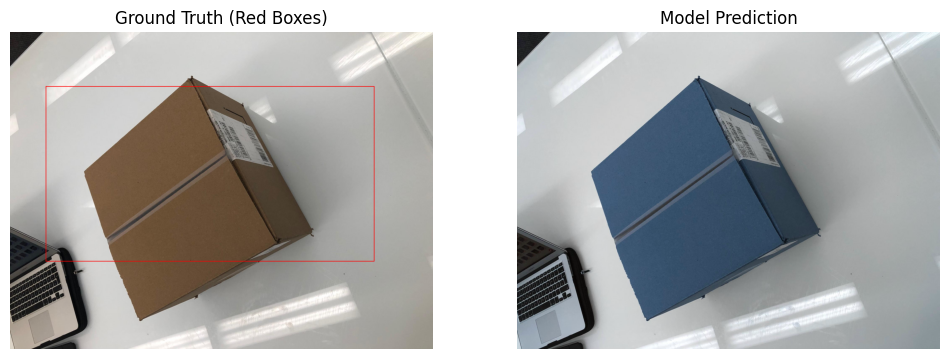


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\person\datasets\images\val\20671.jpg: 640x640 1 Door, 195.0ms
Speed: 5.6ms preprocess, 195.0ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


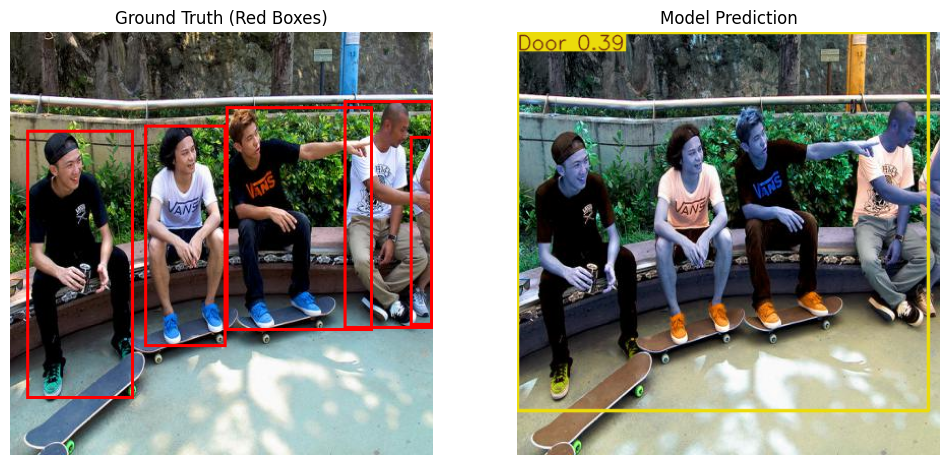

In [13]:
# iterate over all non-door dataset folders
dataset_names = ['parcels', 'person']

plot_test_inference(dataset_names, door_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\val\8028.jpg: 192x640 (no detections), 109.2ms
Speed: 2.0ms preprocess, 109.2ms inference, 1.0ms postprocess per image at shape (1, 3, 192, 640)


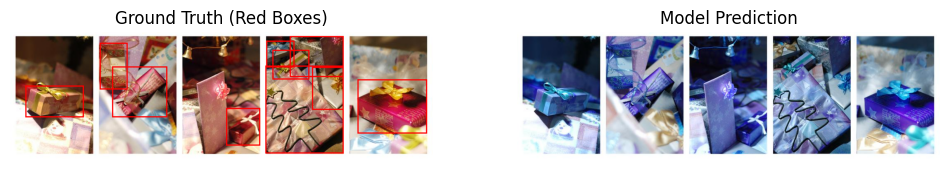

In [212]:
# iterate over all non-door dataset folders
dataset_names = ['parcels']

plot_test_inference(dataset_names, door_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\train\1168.jpg: 640x480 1 Door, 108.7ms
Speed: 3.0ms preprocess, 108.7ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 480)


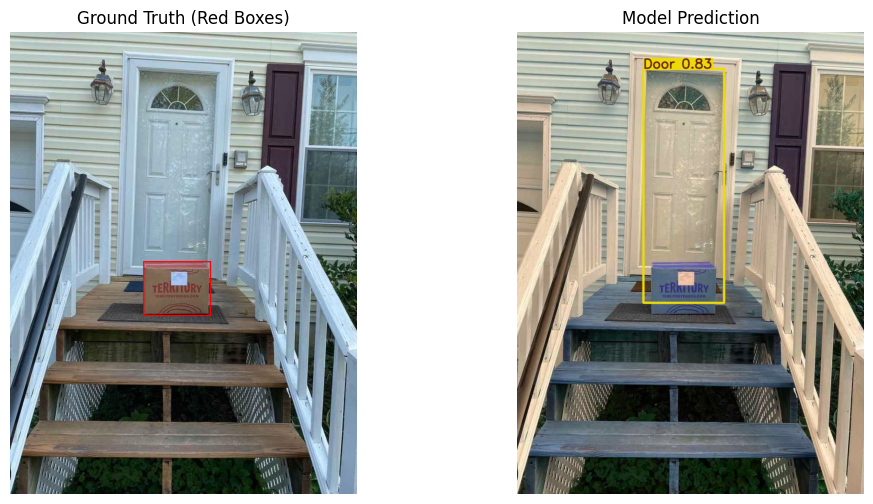

In [213]:
test_image_path = r"separate_datasets_inv11\parcels\datasets\images\train\1168.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, door_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\train\1250.jpg: 640x480 1 Door, 92.9ms
Speed: 2.0ms preprocess, 92.9ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 480)


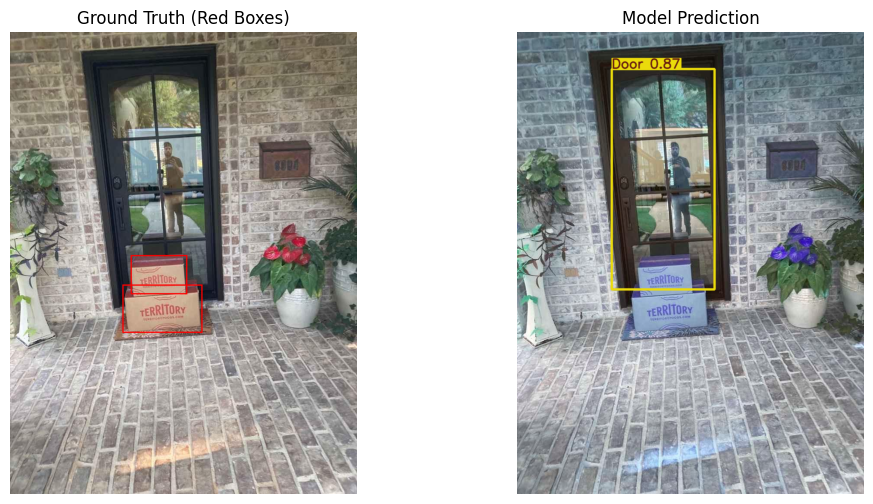

In [214]:
test_image_path = r"separate_datasets_inv11\parcels\datasets\images\train\1250.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, door_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\person\datasets\images\val\21559.jpg: 640x640 1 Door, 238.0ms
Speed: 0.0ms preprocess, 238.0ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


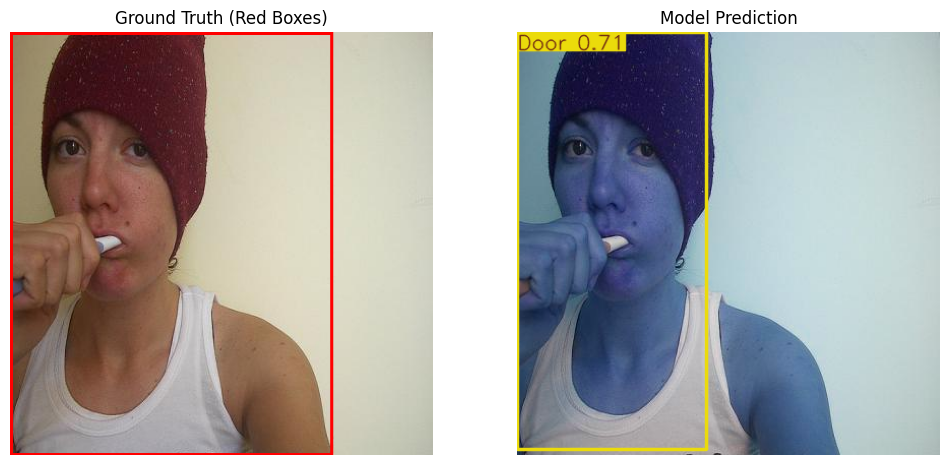

In [134]:
# iterate over all non-door dataset folders
dataset_names = ['person']

plot_test_inference(dataset_names, door_model)

#### Door model v3

In [89]:
door_model_v3 = YOLO("sep_models/door_model_v3.pt", task = 'detect')

It still detects doors.


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\train\1250.jpg: 640x480 1 Door, 121.6ms
Speed: 0.0ms preprocess, 121.6ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 480)


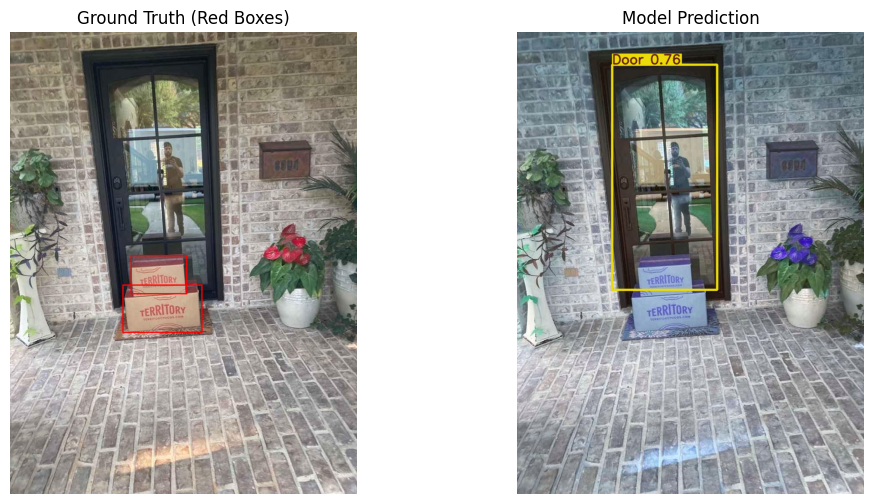

In [91]:
test_image_path = r"separate_datasets_inv11\parcels\datasets\images\train\1250.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, door_model_v3)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\train\1168.jpg: 640x480 2 Doors, 111.1ms
Speed: 0.0ms preprocess, 111.1ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 480)


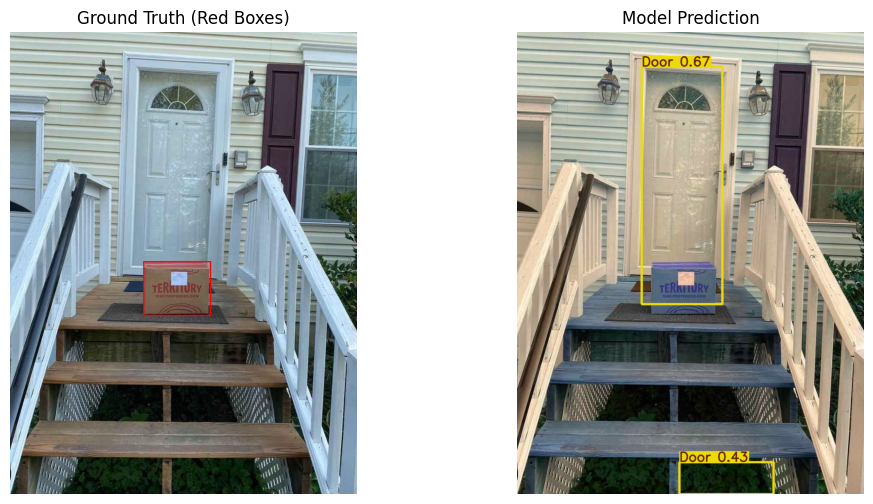

In [92]:
test_image_path = r"separate_datasets_inv11\parcels\datasets\images\train\1168.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, door_model_v3)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\person\datasets\images\val\20671.jpg: 640x640 (no detections), 111.4ms
Speed: 5.0ms preprocess, 111.4ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


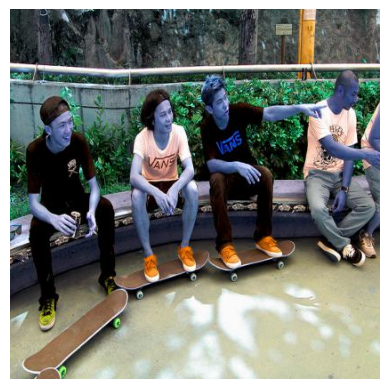

In [93]:
test_image = r"separate_datasets_inv11\person\datasets\images\val\20671.jpg"
plot_prediction_image(test_image, door_model_v3)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\person\datasets\images\val\21559.jpg: 640x640 (no detections), 134.3ms
Speed: 10.0ms preprocess, 134.3ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


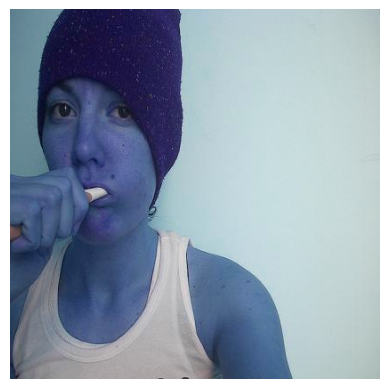

In [136]:
test_image = r"separate_datasets_inv11\person\datasets\images\val\21559.jpg"
plot_prediction_image(test_image, door_model_v3)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\person\datasets\images\val\23124.jpg: 640x640 2 Doors, 198.0ms
Speed: 8.9ms preprocess, 198.0ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 640)


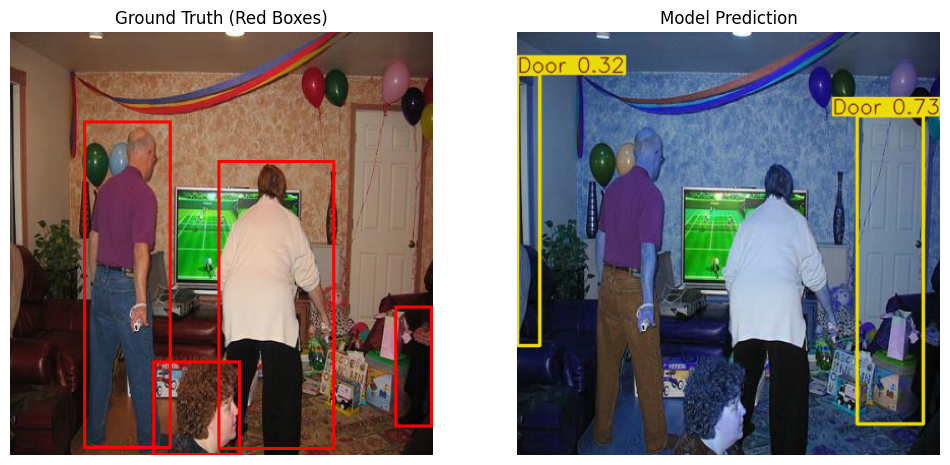

In [100]:
# iterate over all non-door dataset folders
dataset_names = ['person']

plot_test_inference(dataset_names, door_model_v3)

image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\person\datasets\images\val\23745.jpg: 640x640 1 Door, 242.0ms
Speed: 17.5ms preprocess, 242.0ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)


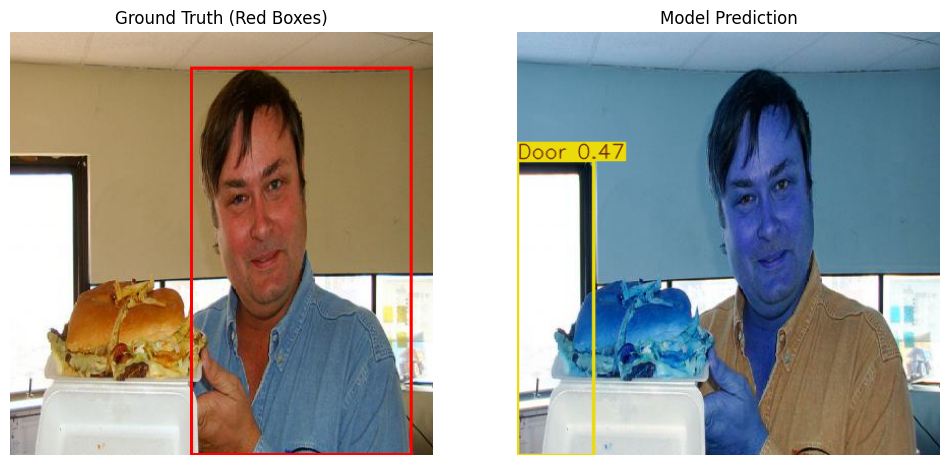

In [113]:
# iterate over all non-door dataset folders
dataset_names = ['person']

plot_test_inference(dataset_names, door_model_v3)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\person\datasets\images\val\22656.jpg: 640x640 1 Door, 166.5ms
Speed: 7.4ms preprocess, 166.5ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


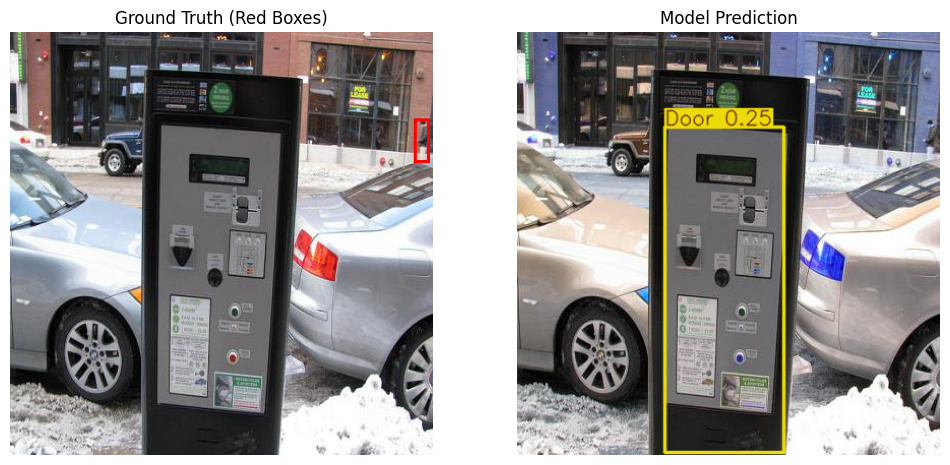

In [114]:
# iterate over all non-door dataset folders
dataset_names = ['person']

plot_test_inference(dataset_names, door_model_v3)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\person\datasets\images\val\23142.jpg: 640x640 (no detections), 145.5ms
Speed: 19.2ms preprocess, 145.5ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


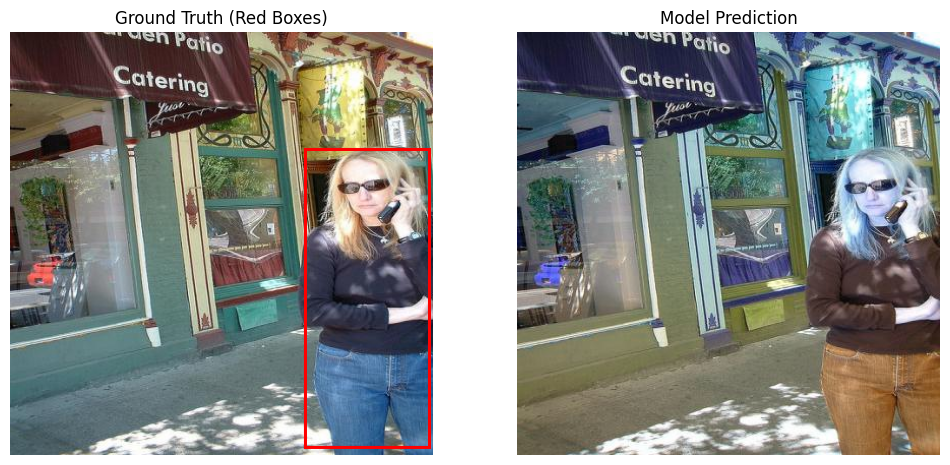

In [123]:
# iterate over all non-door dataset folders
dataset_names = ['person']

plot_test_inference(dataset_names, door_model_v3)

In [ ]:
images_folder = "test_images"
labels_folder = "test_labels"
model_path = "v11best_float32.tflite"
conf = 0.25

relabel(images_folder, labels_folder, model_path, conf)

### Label Parcels

In [85]:
parcel_model = YOLO("sep_models/parcels_model.pt", task = 'detect')


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\doors\datasets\images\val\32609.jpg: 640x640 (no detections), 224.5ms
Speed: 0.0ms preprocess, 224.5ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


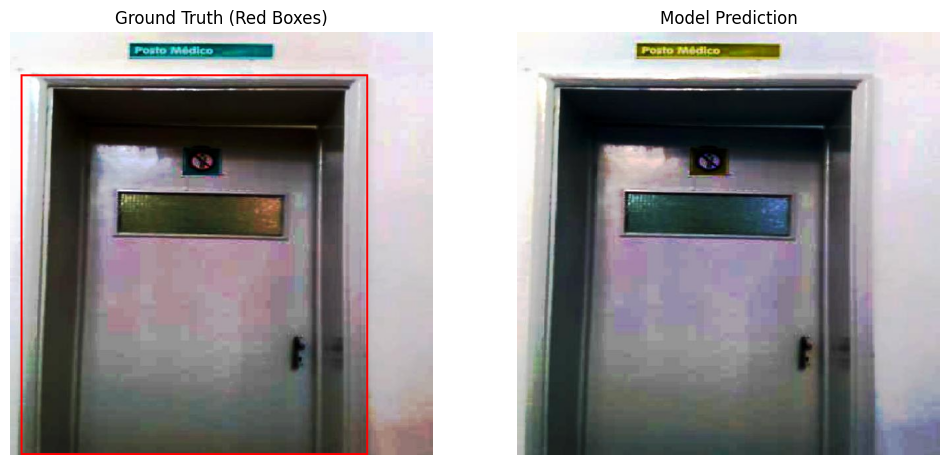

In [86]:
# iterate over all non-door dataset folders
dataset_names = ['doors', 'person', 'numbers_svhn']
dataset_names = ['doors']

plot_test_inference(dataset_names, parcel_model)

image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\doors\datasets\images\train\35057.jpg: 640x480 13 Parcels, 147.6ms
Speed: 0.0ms preprocess, 147.6ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)


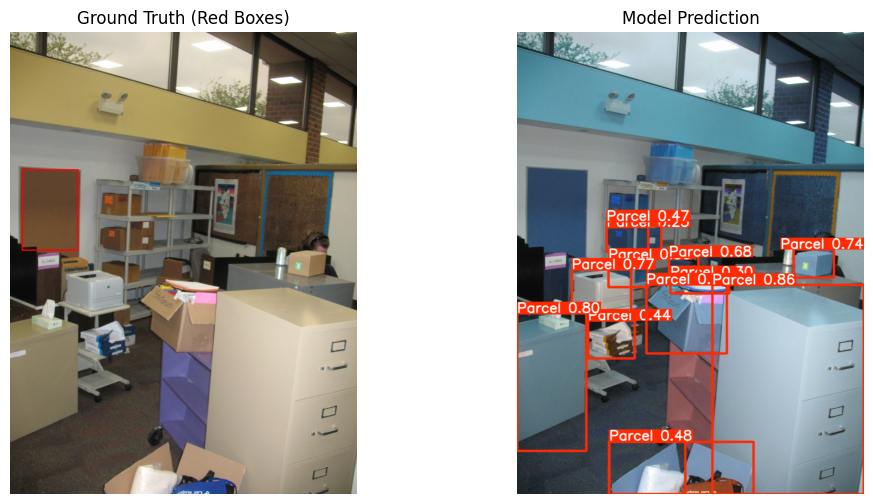

In [88]:
test_image_path = r"separate_datasets_inv11\doors\datasets\images\train\35057.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, parcel_model)

### Label Numbers

In [7]:
numbers_model = YOLO("sep_models/numbers_model.pt", task = 'detect')


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\numbers_svhn\datasets\images\val\svhn_21627.jpg: 640x640 3 Numbers, 264.0ms
Speed: 7.8ms preprocess, 264.0ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


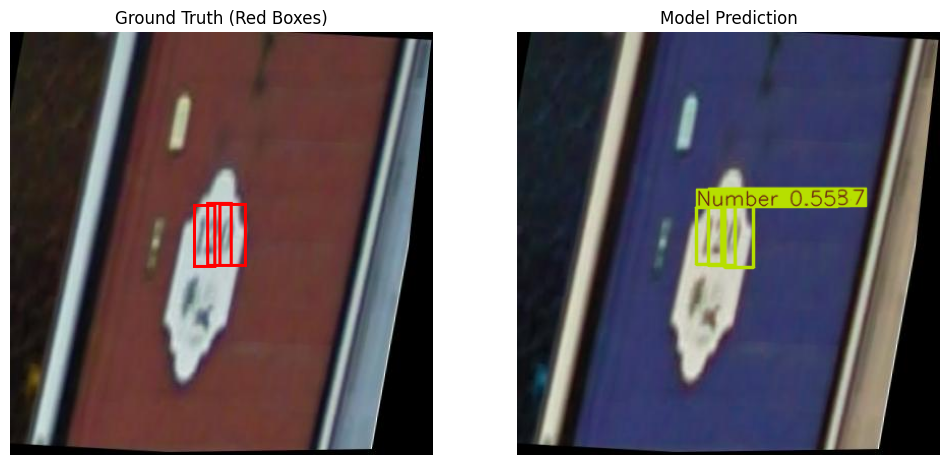

In [63]:
# iterate over all non-door dataset folders
dataset_names = ['numbers_svhn']

plot_test_inference(dataset_names, numbers_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\doors\datasets\images\val\32629.jpg: 640x640 (no detections), 196.8ms
Speed: 7.5ms preprocess, 196.8ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


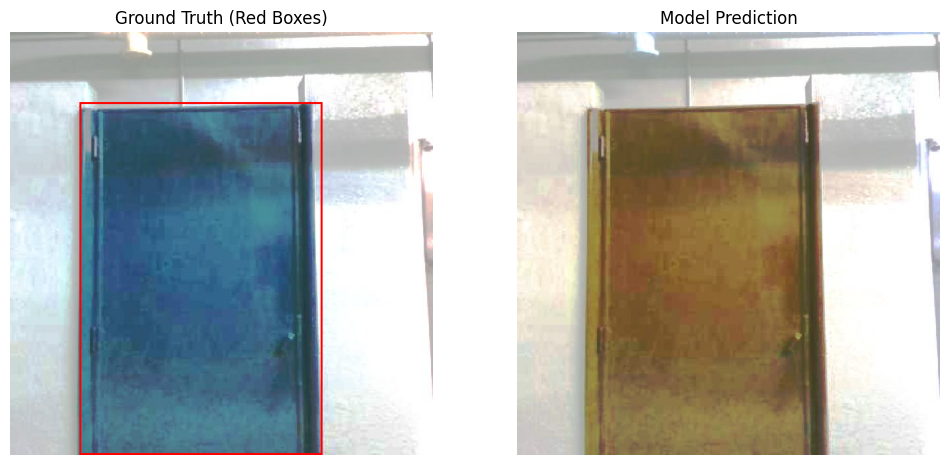


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\val\5979.jpg: 448x640 (no detections), 173.1ms
Speed: 3.5ms preprocess, 173.1ms inference, 0.0ms postprocess per image at shape (1, 3, 448, 640)


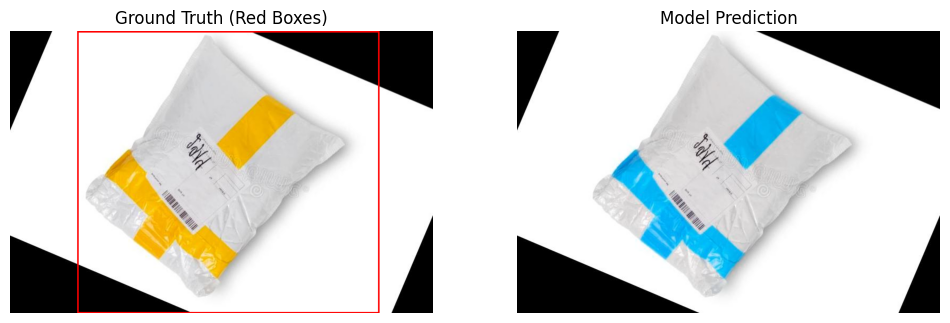


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\person\datasets\images\val\20573.jpg: 640x640 (no detections), 235.7ms
Speed: 0.0ms preprocess, 235.7ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


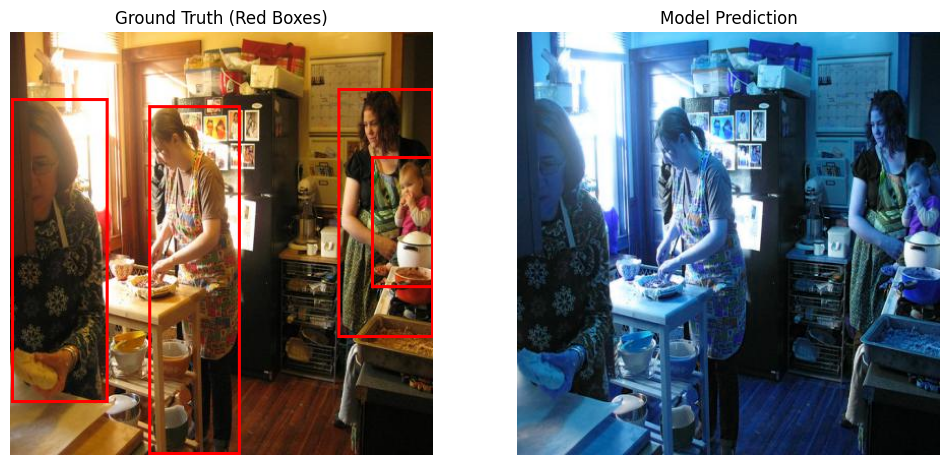

In [18]:
# iterate over all non-door dataset folders
dataset_names = ['doors', 'parcels', 'person']

plot_test_inference(dataset_names, numbers_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\doors\datasets\images\val\32393.jpg: 640x640 (no detections), 262.2ms
Speed: 8.1ms preprocess, 262.2ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 640)


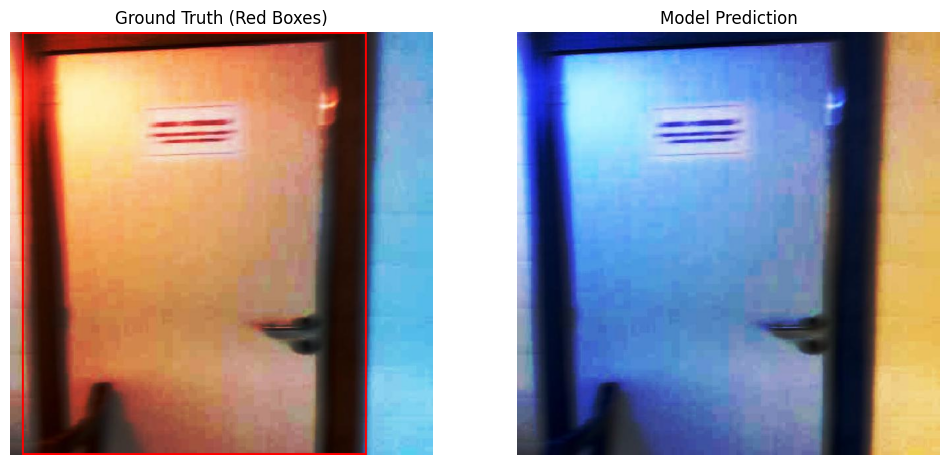

In [32]:
dataset_names = ['doors']
plot_test_inference(dataset_names, numbers_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\doors\datasets\images\train\30028.jpg: 640x640 (no detections), 167.1ms
Speed: 4.4ms preprocess, 167.1ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


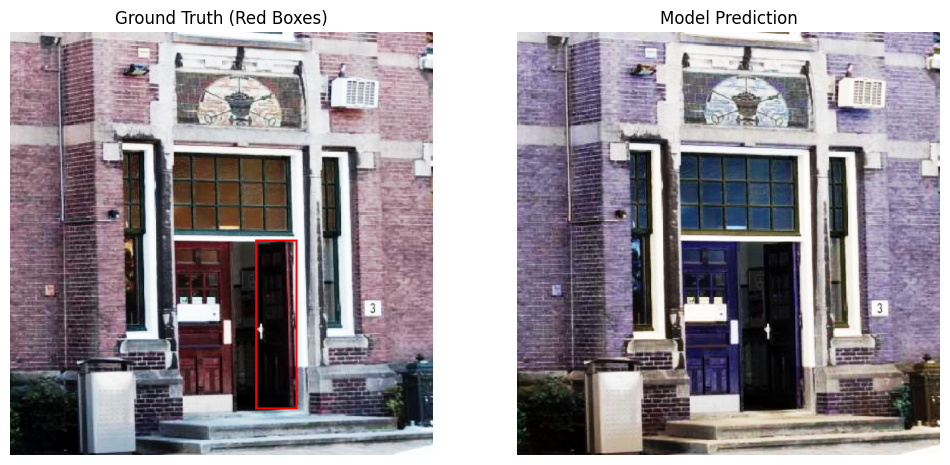

In [34]:
test_image_path = r"separate_datasets_inv11\doors\datasets\images\train\30028.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, numbers_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\doors\datasets\images\train\30038.jpg: 640x640 (no detections), 269.5ms
Speed: 1.8ms preprocess, 269.5ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


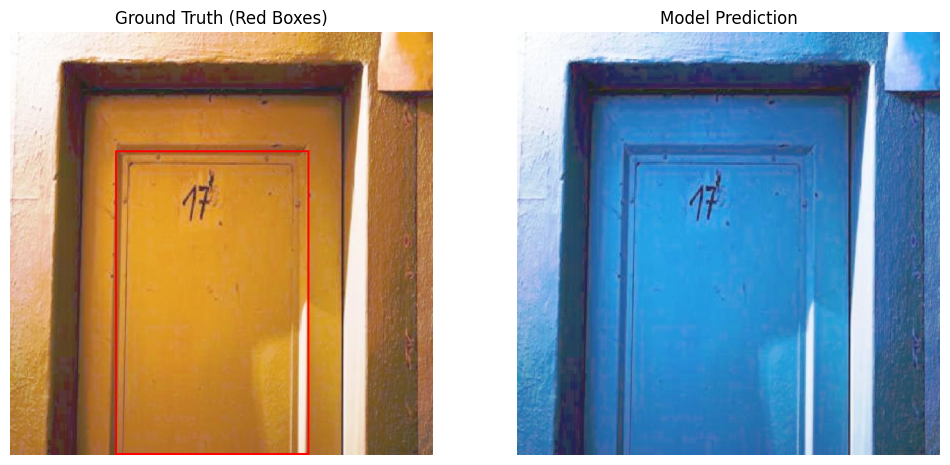

In [35]:
test_image_path = r"separate_datasets_inv11\doors\datasets\images\train\30038.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, numbers_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\doors\datasets\images\train\30202.jpg: 640x640 (no detections), 332.1ms
Speed: 0.0ms preprocess, 332.1ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


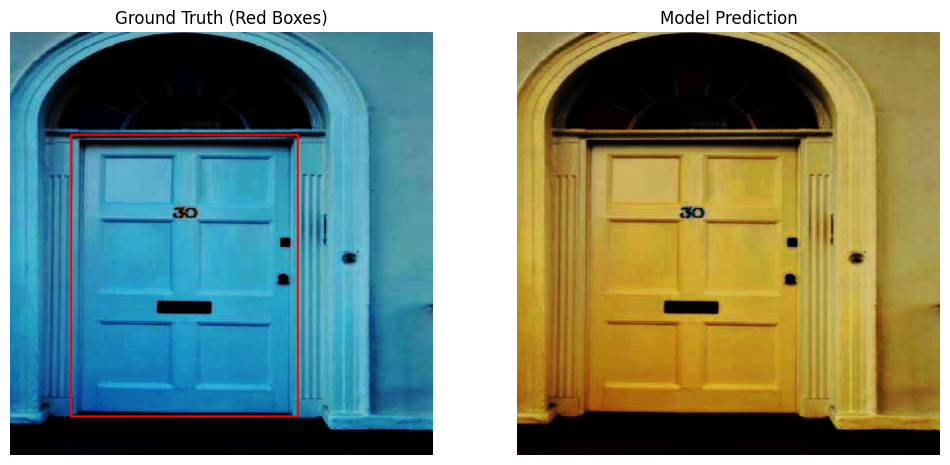

In [36]:
test_image_path = r"separate_datasets_inv11\doors\datasets\images\train\30202.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, numbers_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\doors\datasets\images\train\30258.jpg: 640x640 (no detections), 298.2ms
Speed: 0.0ms preprocess, 298.2ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


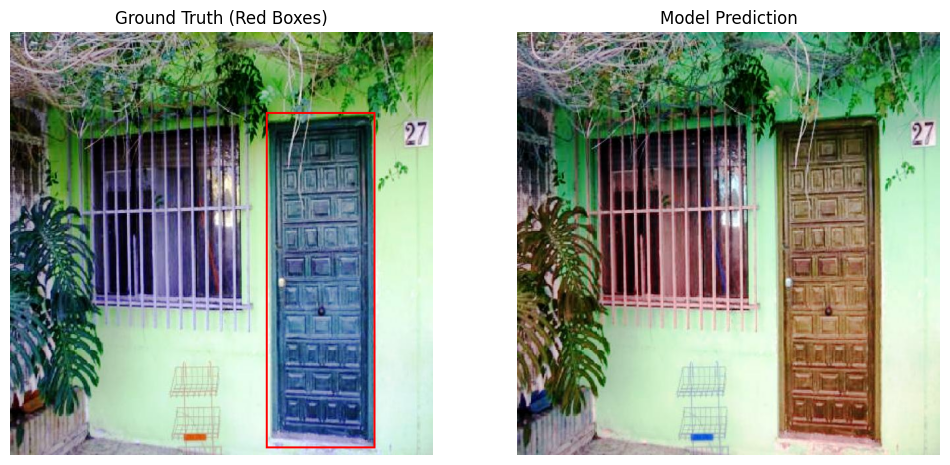

In [38]:
test_image_path = r"separate_datasets_inv11\doors\datasets\images\train\30258.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, numbers_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\doors\datasets\images\train\30663.jpg: 640x640 (no detections), 228.4ms
Speed: 9.0ms preprocess, 228.4ms inference, 15.9ms postprocess per image at shape (1, 3, 640, 640)


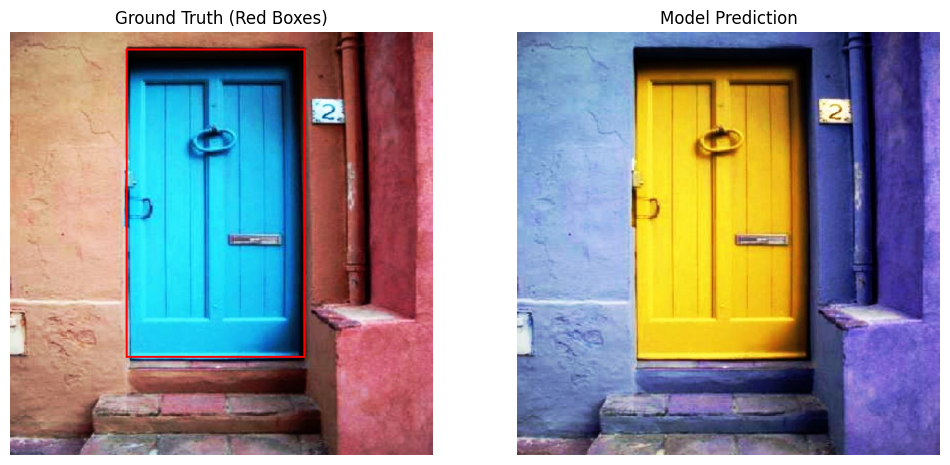

In [39]:
test_image_path = r"separate_datasets_inv11\doors\datasets\images\train\30663.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, numbers_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\test_images\cropped_num_test.jpg: 640x640 (no detections), 168.4ms
Speed: 7.5ms preprocess, 168.4ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


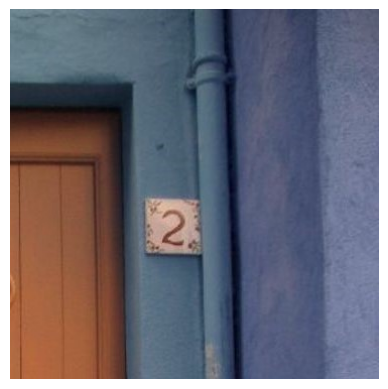

In [83]:
plot_prediction_image("test_images/cropped_num_test.jpg", numbers_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\test_images\original_test_house_num.jpg: 640x640 (no detections), 177.3ms
Speed: 0.0ms preprocess, 177.3ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


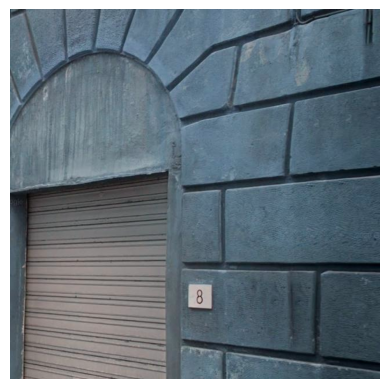

In [84]:
plot_prediction_image("test_images/original_test_house_num.jpg", numbers_model)

### Label People

In [41]:
people_model = YOLO("sep_models/people_model.pt", task = 'detect')


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\doors\datasets\images\val\33118.jpg: 640x640 (no detections), 305.9ms
Speed: 8.5ms preprocess, 305.9ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)


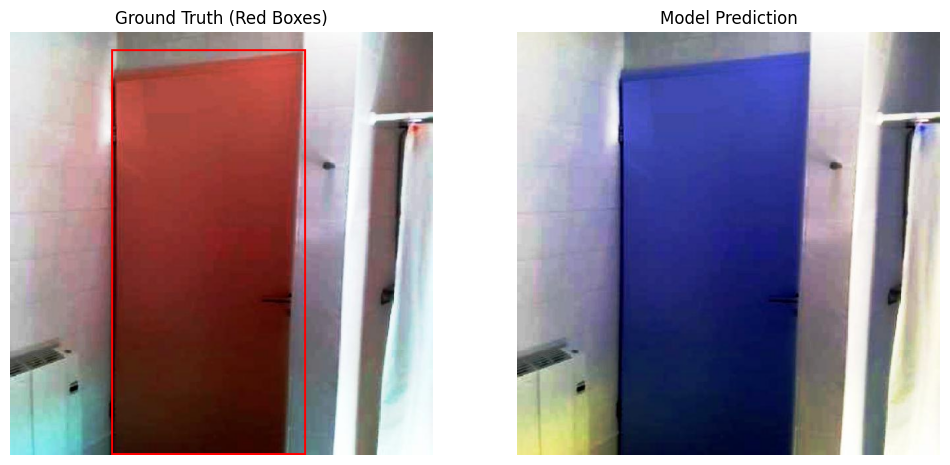


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\val\8130.jpg: 640x640 (no detections), 341.3ms
Speed: 6.0ms preprocess, 341.3ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 640)


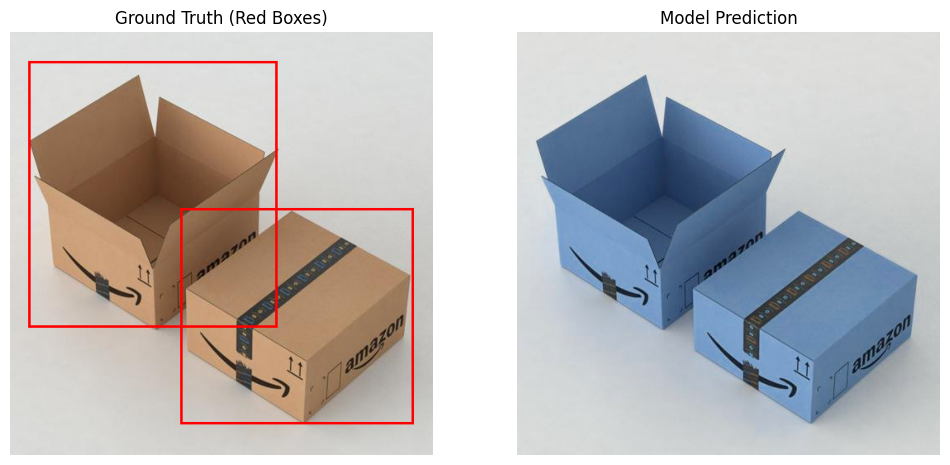


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\numbers_svhn\datasets\images\val\svhn_8942.jpg: 640x640 (no detections), 255.1ms
Speed: 7.0ms preprocess, 255.1ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)


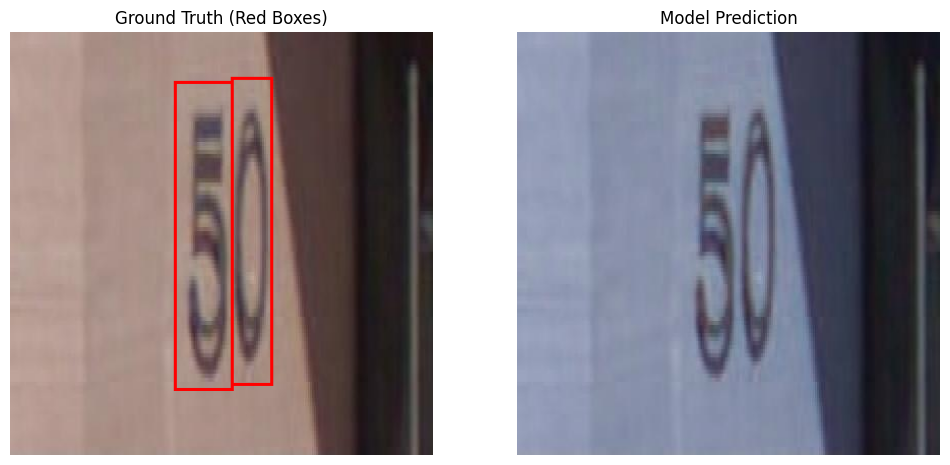

In [72]:
# iterate over all non-door dataset folders
dataset_names = ['doors', 'parcels', 'numbers_svhn']

plot_test_inference(dataset_names, people_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\doors\datasets\images\train\30707.jpg: 640x640 1 Person, 250.5ms
Speed: 0.0ms preprocess, 250.5ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


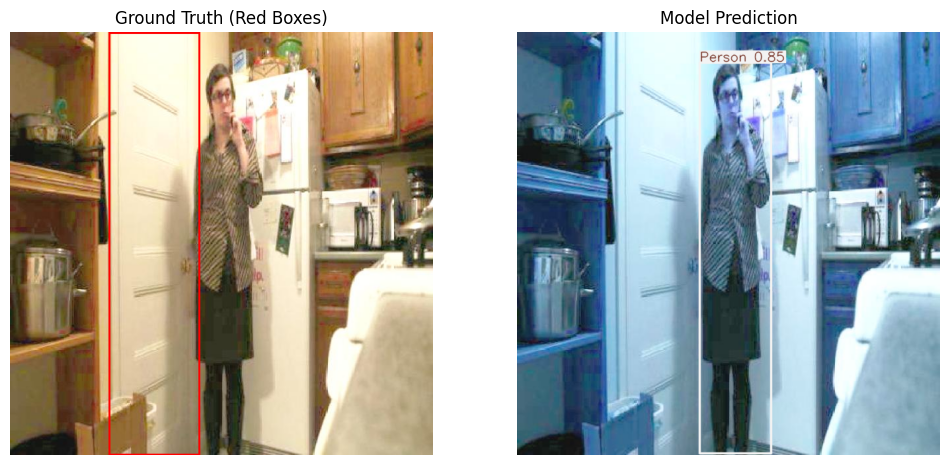

In [74]:
test_image_path = r"separate_datasets_inv11\doors\datasets\images\train\30707.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, people_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\doors\datasets\images\train\31256.jpg: 640x640 1 Person, 533.8ms
Speed: 15.5ms preprocess, 533.8ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


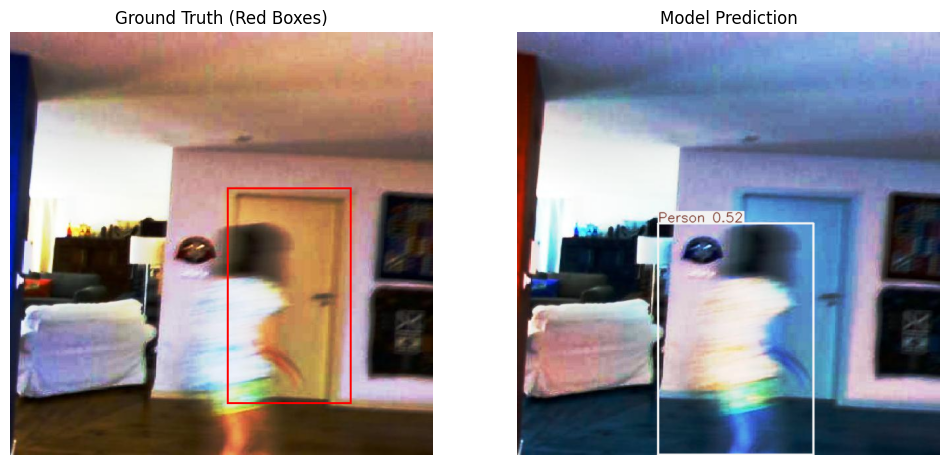

In [75]:
test_image_path = r"separate_datasets_inv11\doors\datasets\images\train\31256.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, people_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\train\486.jpg: 640x448 3 Persons, 373.9ms
Speed: 9.3ms preprocess, 373.9ms inference, 8.1ms postprocess per image at shape (1, 3, 640, 448)


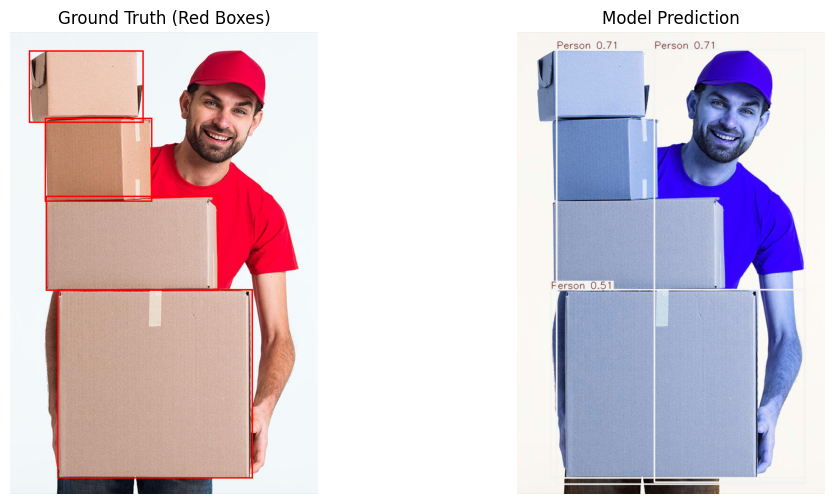

In [76]:
test_image_path = r"separate_datasets_inv11\parcels\datasets\images\train\486.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, people_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\train\551.jpg: 416x640 2 Persons, 203.9ms
Speed: 1.8ms preprocess, 203.9ms inference, 0.0ms postprocess per image at shape (1, 3, 416, 640)


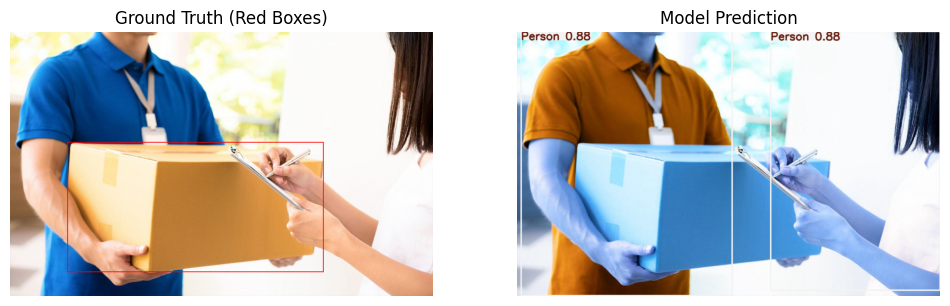

In [77]:
test_image_path = r"separate_datasets_inv11\parcels\datasets\images\train\551.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, people_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\train\595.jpg: 448x640 1 Person, 198.5ms
Speed: 0.0ms preprocess, 198.5ms inference, 0.0ms postprocess per image at shape (1, 3, 448, 640)


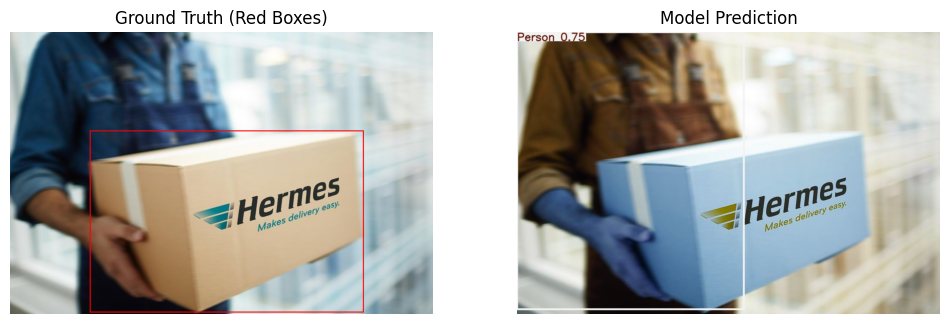

In [78]:
test_image_path = r"separate_datasets_inv11\parcels\datasets\images\train\595.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, people_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\train\644.jpg: 448x640 2 Persons, 205.2ms
Speed: 0.0ms preprocess, 205.2ms inference, 0.0ms postprocess per image at shape (1, 3, 448, 640)


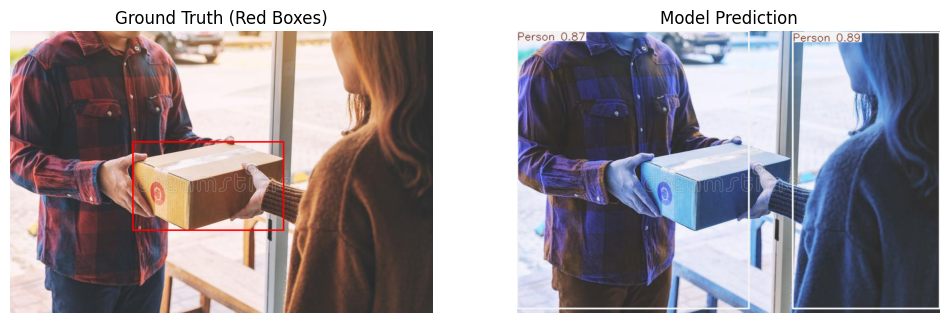

In [79]:
test_image_path = r"separate_datasets_inv11\parcels\datasets\images\train\644.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, people_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\train\706.jpg: 640x608 1 Person, 217.7ms
Speed: 8.3ms preprocess, 217.7ms inference, 8.0ms postprocess per image at shape (1, 3, 640, 608)


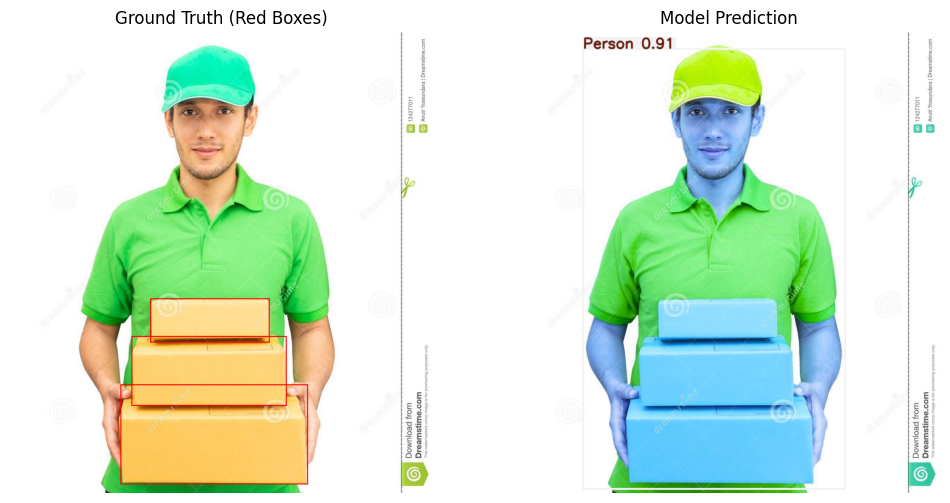

In [80]:
test_image_path = r"separate_datasets_inv11\parcels\datasets\images\train\706.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, people_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\train\874.jpg: 544x640 (no detections), 234.2ms
Speed: 16.5ms preprocess, 234.2ms inference, 0.0ms postprocess per image at shape (1, 3, 544, 640)


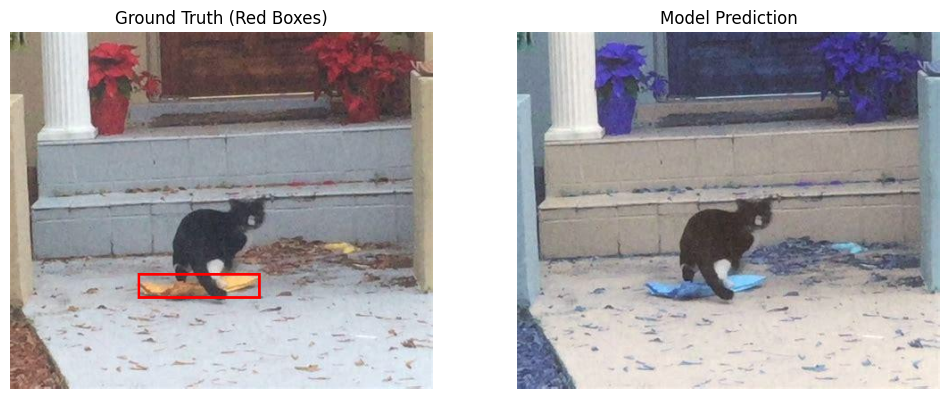

In [81]:
test_image_path = r"separate_datasets_inv11\parcels\datasets\images\train\874.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, people_model)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\separate_datasets_inv11\parcels\datasets\images\train\1006.jpg: 512x640 1 Person, 199.6ms
Speed: 4.0ms preprocess, 199.6ms inference, 2.0ms postprocess per image at shape (1, 3, 512, 640)


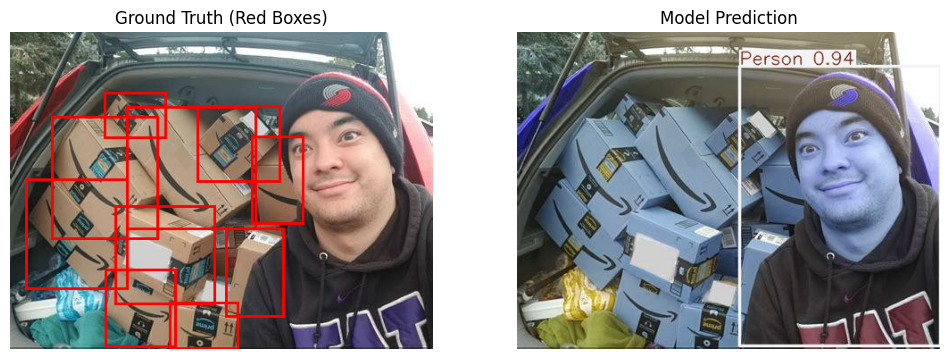

In [82]:
test_image_path = r"separate_datasets_inv11\parcels\datasets\images\train\1006.jpg"
test_label_path = test_image_path.replace("images", "labels").replace(".jpg", ".txt")
plot_ground_truth_vs_prediction(test_image_path, test_label_path, people_model)

# Relabel Parcel Dataset

With people and doors models

## Test on subset

In [18]:
def has_full_image_bbox(result):
    full_image_bbox = False
    for (x, y, w, h) in result.boxes.xywh:
        print(x, y, w, h)
        image_height = result.orig_shape[0]
        image_width = result.orig_shape[1]
        # fuzzy match the w and image_width 90%
        if (image_width * 0.9 < w) and (image_height * 0.9 < h):
            full_image_bbox = True
            break
    return full_image_bbox

In [16]:
parcel_train_image_dir = r"separate_datasets_inv11\parcels\datasets\images\train"
subset_dir = f"test_inference_folder\parcels\images"

get_subset(parcel_train_image_dir, subset_dir, 100)

100%|██████████| 100/100 [00:00<00:00, 316.17it/s]

Done copying 100 files to test_inference_folder\parcels\images


In [ ]:
model = YOLO("sep_models/people_model.pt", task = 'detect')
subset_dir = f"test_inference_folder\parcels\images"

for image in os.listdir(subset_dir):
    if image.lower().endswith(('.jpg', '.png', '.jpeg')):  # Ensure only image files are processed
        image_path = os.path.join(subset_dir, image)
        results_path = image_path.replace("images", "results")
        result = model.predict(image_path, conf=0.5)[0]
        result.save(results_path)


In [ ]:
model = YOLO("sep_models/door_model_v3.pt", task = 'detect')
subset_dir = r"test_inference_folder\parcels\images"

for image in os.listdir(subset_dir):
    if image.lower().endswith(('.jpg', '.png', '.jpeg')):  # Ensure only image files are processed
        image_path = os.path.join(subset_dir, image)
        results_path = image_path.replace("images", "results_door_025")
        result = model.predict(image_path, conf=0.25)[0]
        print(result.boxes)
        if has_full_image_bbox(result):
            print(f"FULL image bbox ALERT for{image_path}")
        result.save(results_path)


## Create relabelled dataset

In [168]:
def relabel_with_full_image_bbox_check(images_folder, labels_folder, model_path, conf):
    model = YOLO(model_path)
    
    for image in os.listdir(images_folder):
        if image.lower().endswith(('.jpg', '.png', '.jpeg')):  # Ensure only image files are processed
            image_path = os.path.join(images_folder, image)
            result = model.predict(image_path, conf=conf)[0]
            label_path = os.path.join(labels_folder, image.rsplit(".", 1)[0] + ".txt")
            if (has_full_image_bbox(result)):
                continue
            result.save_txt(label_path)

### Label peoples onto parcels dataset

In [ ]:
image_dir = "relabelled_datasets/parcels/datasets/images/val"
relabel_with_full_image_bbox_check(image_dir, image_dir.replace('images', 'labels'), "sep_models/people_model.pt", 0.6)

In [ ]:
image_dir = "relabelled_datasets/parcels/datasets/images/train"
relabel_with_full_image_bbox_check(image_dir, image_dir.replace('images', 'labels'), "sep_models/people_model.pt", 0.6)

### Label doors onto parcels dataset

In [ ]:
image_dir = "relabelled_datasets/parcels/datasets/images/val"
relabel_with_full_image_bbox_check(image_dir, image_dir.replace('images', 'labels'), "sep_models/door_model_v3.pt", 0.6)

In [ ]:
image_dir = "relabelled_datasets/parcels/datasets/images/train"
relabel_with_full_image_bbox_check(image_dir, image_dir.replace('images', 'labels'), "sep_models/door_model_v3.pt", 0.6)

## Test Labels

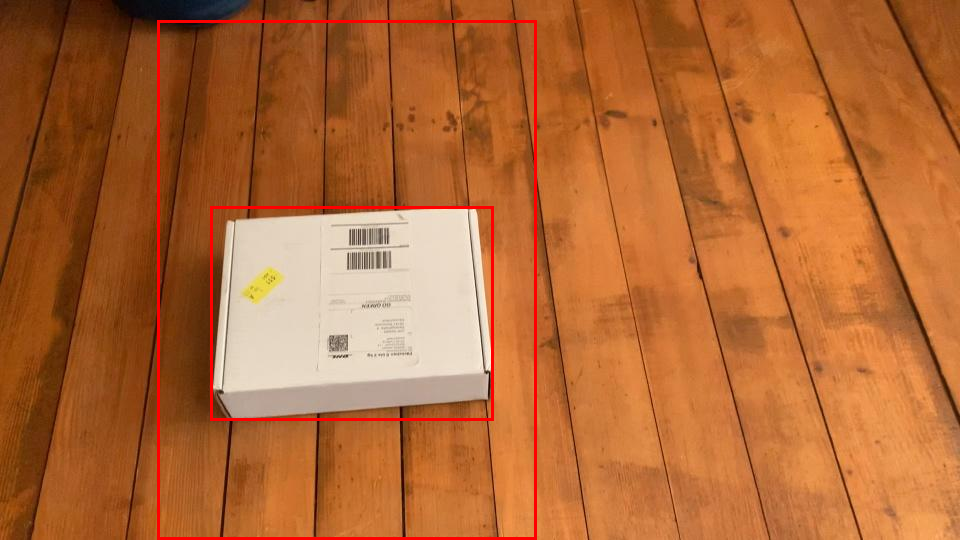

In [185]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\8589.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
draw_ground_truth(image_file, label_file)

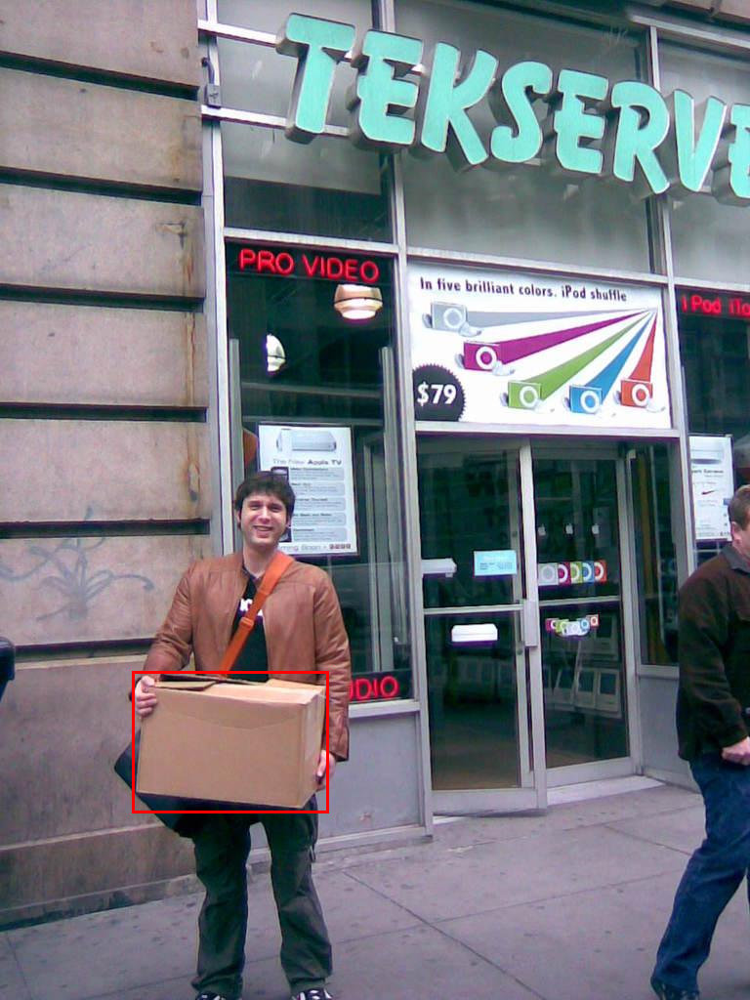

In [9]:
image_file = r"separate_datasets_inv11\parcels\datasets\images\val\7485.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
draw_ground_truth(image_file, label_file)

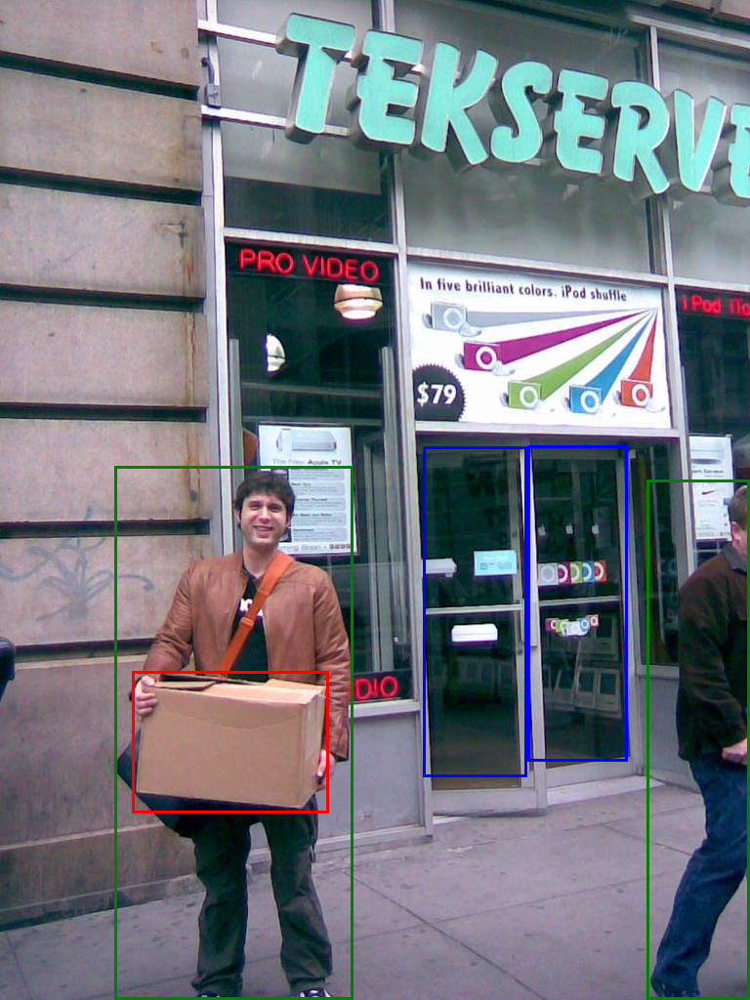

In [10]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\7485.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
draw_ground_truth(image_file, label_file)

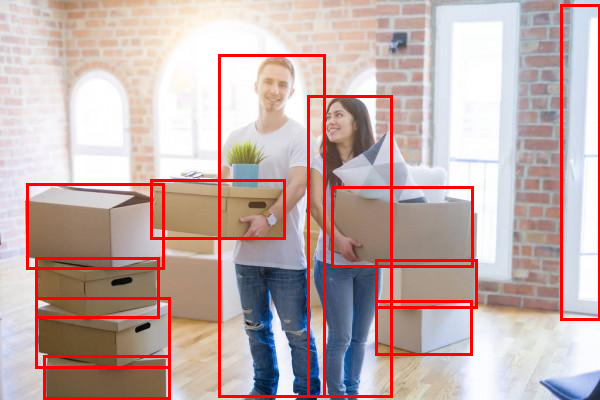

In [184]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\7067.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
draw_ground_truth(image_file, label_file)

# Relabel doors dataset

With people and parcels

In [19]:
doors_train_image_dir = r"separate_datasets_inv11\doors\datasets\images\train"
subset_dir = f"test_inference_folder\doors\images"

get_subset(doors_train_image_dir, subset_dir, 100)

100%|██████████| 100/100 [00:00<00:00, 366.14it/s]

Done copying 100 files to test_inference_folder\doors\images


### Label people onto doors dataset

Testing on subset

In [ ]:
model = YOLO("sep_models/people_model.pt", task = 'detect')
subset_dir = r"test_inference_folder\doors\images"

for image in os.listdir(subset_dir):
    if image.lower().endswith(('.jpg', '.png', '.jpeg')):  # Ensure only image files are processed
        image_path = os.path.join(subset_dir, image)
        results_path = image_path.replace("images", "results")
        result = model.predict(image_path, conf=0.55)[0]
        if has_full_image_bbox(result):
            print(f"FULL image bbox ALERT for{image_path}")
        result.save(results_path)


### Label parcels onto doors dataset

Testing on subset

In [ ]:
model = YOLO("sep_models/parcels_model.pt", task = 'detect')
subset_dir = r"test_inference_folder\doors\images"

for image in os.listdir(subset_dir):
    if image.lower().endswith(('.jpg', '.png', '.jpeg')):  # Ensure only image files are processed
        image_path = os.path.join(subset_dir, image)
        results_path = image_path.replace("images", "results_parcels")
        result = model.predict(image_path, conf=0.25)[0]
        if has_full_image_bbox(result):
            print(f"FULL image bbox ALERT for{image_path}")
        result.save(results_path)


# Relabel people dataset
With parcels and doors

In [26]:
people_train_image_dir = r"separate_datasets_inv11\person\datasets\images\train"
subset_dir = f"test_inference_folder\people\images"

get_subset(people_train_image_dir, subset_dir, 100)

100%|██████████| 100/100 [00:00<00:00, 287.42it/s]

Done copying 100 files to test_inference_folder\people\images


In [ ]:
model = YOLO("sep_models/door_model.pt", task = 'detect')
subset_dir = r"test_inference_folder\doors\images"

for image in os.listdir(subset_dir):
    if image.lower().endswith(('.jpg', '.png', '.jpeg')):  # Ensure only image files are processed
        image_path = os.path.join(subset_dir, image)
        results_path = image_path.replace("images", "results_door")
        result = model.predict(image_path, conf=0.25)[0]
        if has_full_image_bbox(result):
            print(f"FULL image bbox ALERT for{image_path}")
        result.save(results_path)


# Test model trained on relabelled data

This model was trained on the relabelled parcel dataset.

In [12]:
model_relabelled_parcel = YOLO('sep_models/parcel_w_other_labels.pt', task = 'detect')
model_original = YOLO('v11best_float32.tflite', task = 'detect')


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\val\7067.jpg: 448x640 9 Parcels, 2 Persons, 132.5ms
Speed: 11.5ms preprocess, 132.5ms inference, 0.0ms postprocess per image at shape (1, 3, 448, 640)


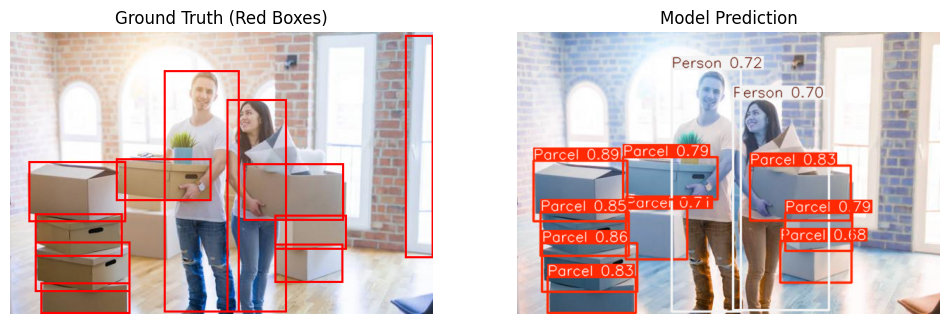

In [24]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\7067.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
plot_ground_truth_vs_prediction(image_file, label_file, model_relabelled_parcel)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\val\7067.jpg: 448x640 9 Parcels, 2 Persons, 102.4ms
Speed: 16.4ms preprocess, 102.4ms inference, 0.0ms postprocess per image at shape (1, 3, 448, 640)


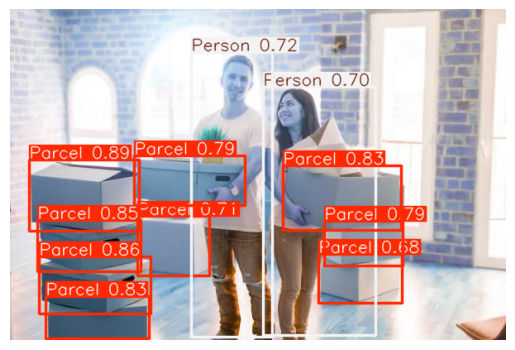

In [13]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\7067.jpg"
plot_prediction_image(image_file, model_relabelled_parcel)

Loading v11best_float32.tflite for TensorFlow Lite inference...

image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\val\7067.jpg: 640x640 11 Parcels, 100.2ms
Speed: 0.0ms preprocess, 100.2ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


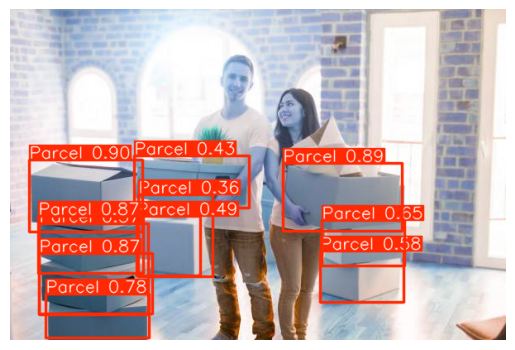

In [14]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\7067.jpg"
plot_prediction_image(image_file, model_original)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\val\7067.jpg: 640x640 11 Parcels, 133.8ms
Speed: 8.6ms preprocess, 133.8ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


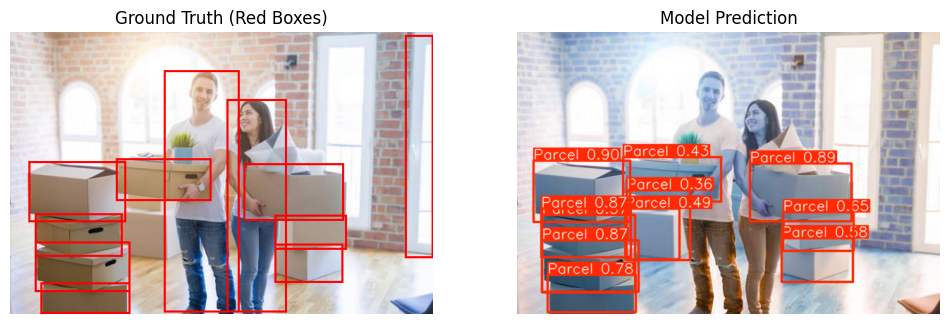

In [25]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\7067.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
plot_ground_truth_vs_prediction(image_file, label_file, model_original)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\val\7485.jpg: 640x480 1 Parcel, 2 Persons, 198.6ms
Speed: 7.3ms preprocess, 198.6ms inference, 5.0ms postprocess per image at shape (1, 3, 640, 480)


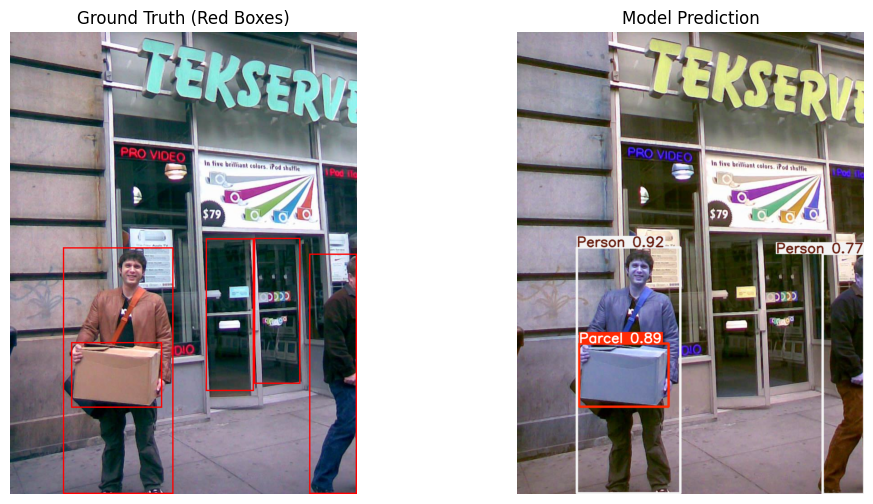

In [26]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\7485.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
plot_ground_truth_vs_prediction(image_file, label_file, model_relabelled_parcel)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\val\7485.jpg: 640x640 1 Parcel, 137.3ms
Speed: 10.7ms preprocess, 137.3ms inference, 9.1ms postprocess per image at shape (1, 3, 640, 640)


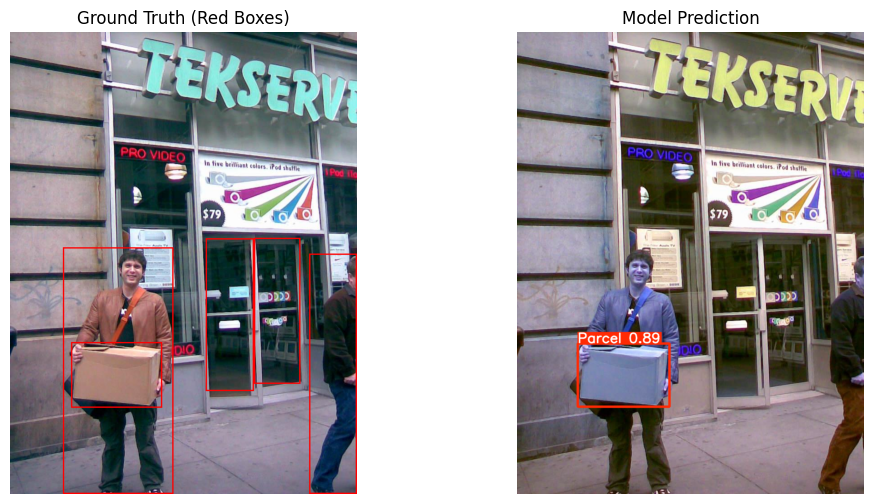

In [27]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\7485.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
plot_ground_truth_vs_prediction(image_file, label_file, model_original)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\val\8589.jpg: 384x640 1 Parcel, 143.8ms
Speed: 7.4ms preprocess, 143.8ms inference, 0.0ms postprocess per image at shape (1, 3, 384, 640)


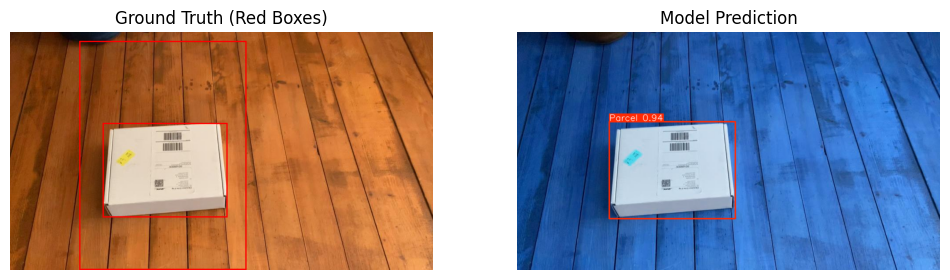

In [28]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\8589.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
plot_ground_truth_vs_prediction(image_file, label_file, model_relabelled_parcel)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\val\8589.jpg: 640x640 1 Parcel, 119.9ms
Speed: 8.2ms preprocess, 119.9ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


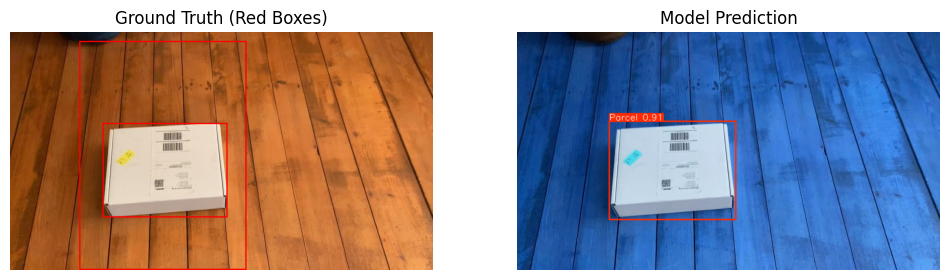

In [29]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\8589.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
plot_ground_truth_vs_prediction(image_file, label_file, model_original)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\train\737.jpg: 640x480 1 Parcel, 1 Door, 140.5ms
Speed: 0.0ms preprocess, 140.5ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 480)


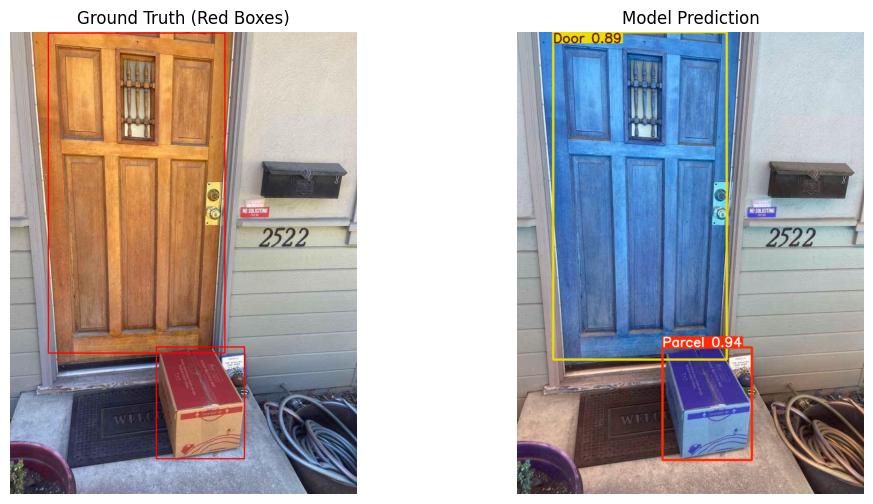

In [30]:
image_file = r"relabelled_datasets\parcels\datasets\images\train\737.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
plot_ground_truth_vs_prediction(image_file, label_file, model_relabelled_parcel)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\train\737.jpg: 640x640 1 Parcel, 123.7ms
Speed: 10.8ms preprocess, 123.7ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


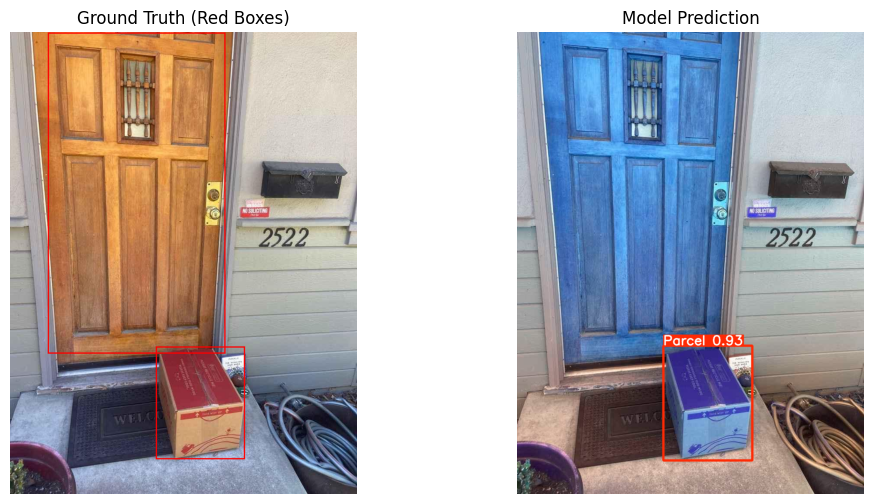

In [31]:
image_file = r"relabelled_datasets\parcels\datasets\images\train\737.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
plot_ground_truth_vs_prediction(image_file, label_file, model_original)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\val\778.jpg: 640x480 1 Parcel, 1 Door, 213.8ms
Speed: 3.9ms preprocess, 213.8ms inference, 2.8ms postprocess per image at shape (1, 3, 640, 480)


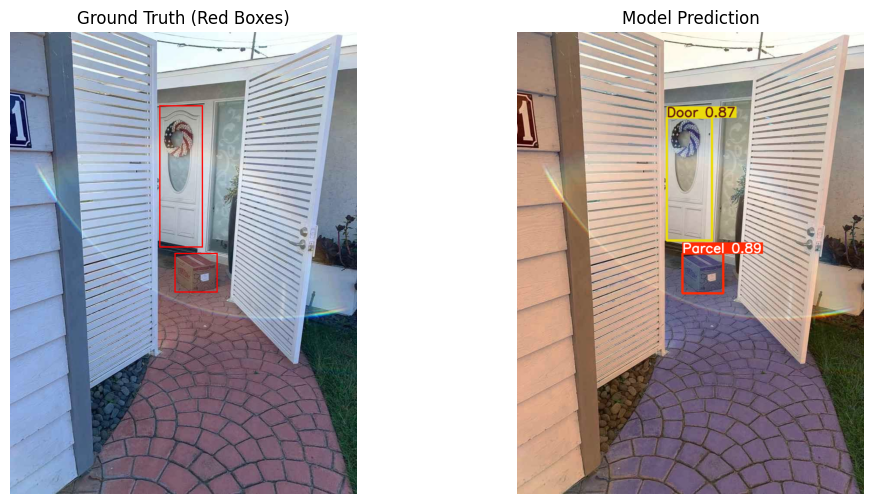

In [32]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\778.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
plot_ground_truth_vs_prediction(image_file, label_file, model_relabelled_parcel)


image 1/1 c:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\val\778.jpg: 640x640 1 Parcel, 123.6ms
Speed: 11.0ms preprocess, 123.6ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)


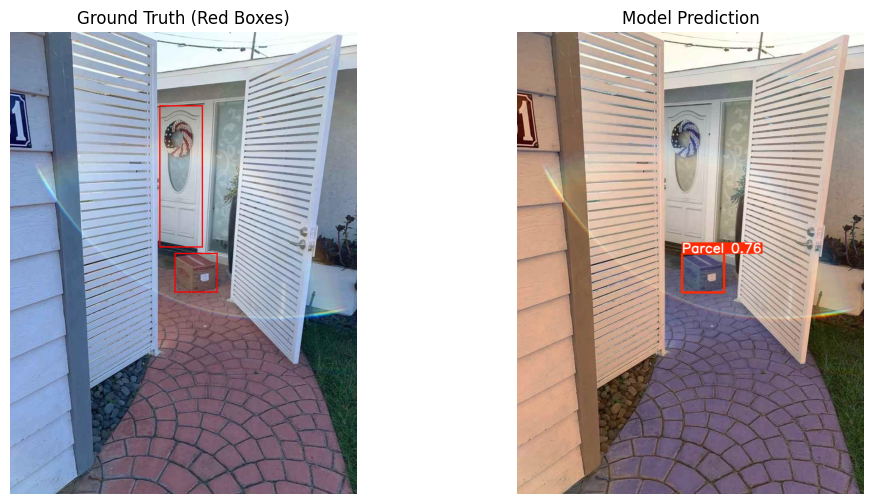

In [33]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\778.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
plot_ground_truth_vs_prediction(image_file, label_file, model_original)


image 1/1 C:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\val\793.jpg: 640x480 2 Parcels, 1 Door, 181.1ms
Speed: 6.1ms preprocess, 181.1ms inference, 3.5ms postprocess per image at shape (1, 3, 640, 480)


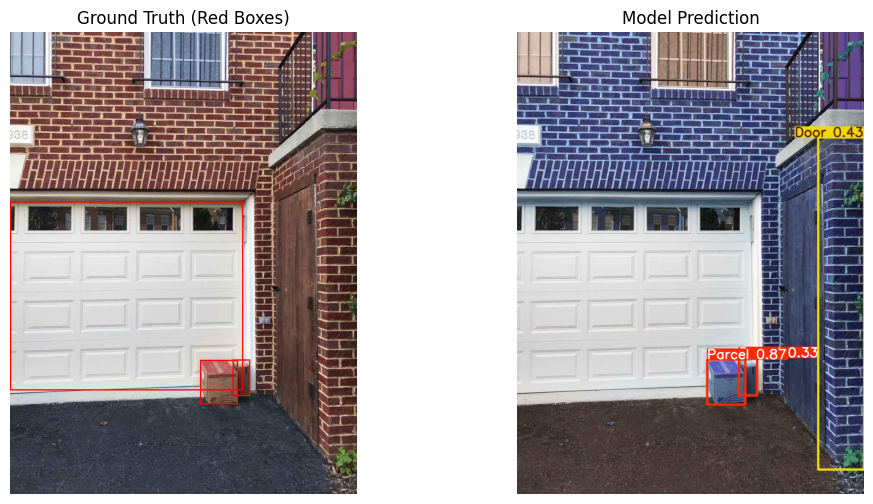

In [34]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\793.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
plot_ground_truth_vs_prediction(image_file, label_file, model_relabelled_parcel)


image 1/1 C:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\val\1089.jpg: 640x480 2 Parcels, 1 Door, 170.8ms
Speed: 13.9ms preprocess, 170.8ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 480)


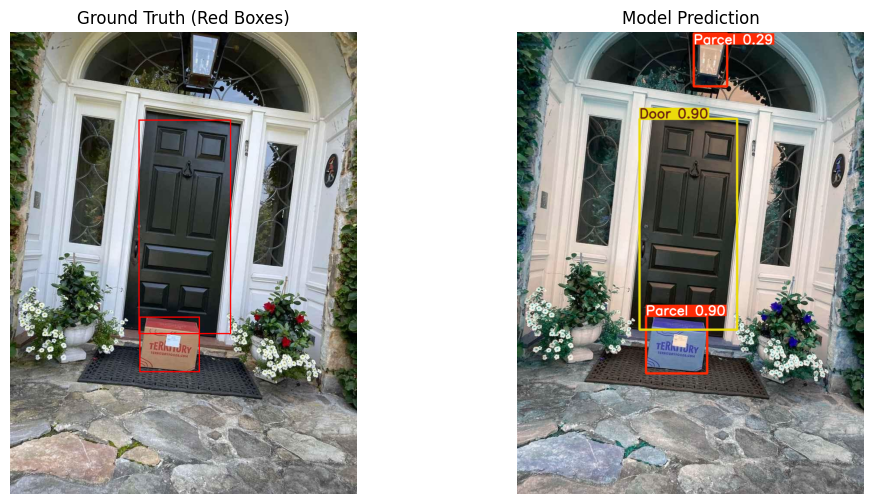

In [35]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\1089.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
plot_ground_truth_vs_prediction(image_file, label_file, model_relabelled_parcel)


image 1/1 C:\Users\BenJordan\Documents\object-detection-YOLOv11\relabelled_datasets\parcels\datasets\images\val\1344.jpg: 640x480 2 Parcels, 210.9ms
Speed: 6.1ms preprocess, 210.9ms inference, 8.1ms postprocess per image at shape (1, 3, 640, 480)


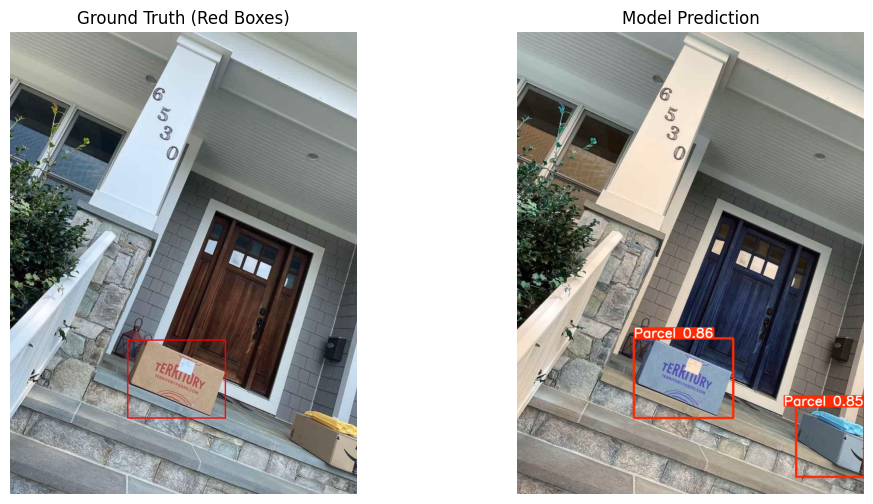

In [36]:
image_file = r"relabelled_datasets\parcels\datasets\images\val\1344.jpg"
label_file = image_file.replace('images', 'labels').replace('.jpg', '.txt')
plot_ground_truth_vs_prediction(image_file, label_file, model_relabelled_parcel)